Supplementary figure: design robustness

In [3]:
# ============================================================
# Supplementary Simulation — Design / robustness stress tests
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import isovita as iso
import isovita_simulation as isim


# ============================================================
# Reference design
# ============================================================

TRUTH_TYPES = (
    "discrete",
    "continuous",
    "localized",
)

MATCHED_BRANCH = {
    "discrete": "discrete",
    "continuous": "continuous",
    "localized": "localized",
}

N_REPLICATES = 20

# 9 alternatives + 9 nulls = 18 genes per simulated dataset.
GENES_PER_TRUTH = 3
N_NULL = len(TRUTH_TYPES) * GENES_PER_TRUTH

REFERENCE_SIGNAL = 0.30

REFERENCE_N = 180
REFERENCE_K = 4
REFERENCE_NOISE_SD = 0.30
REFERENCE_NOISE_CORR = 0.10
REFERENCE_AGE_DESIGN = "uniform"
REFERENCE_BASELINE_STYLE = "heterogeneous"

ALPHA_FDR = 0.05

# 18 genes × 4 localized windows = 72 hypotheses.
# 1/(1500+1) ~= 0.000666
# 0.05/72 ~= 0.000694
N_PERMUTATIONS = 1500

BASE_SEED = 20260927


# Canonical temporal geometry.
TRUE_CHANGE_AGE = 35.0

CONTINUOUS_CENTER = 42.0
CONTINUOUS_SCALE = 16.0

LOCALIZED_CENTER = 30.0
LOCALIZED_WIDTH = 5.0


# ============================================================
# One-factor-at-a-time stress grid
# ============================================================

ROBUSTNESS_GRID = {
    "sample_size": [
        60,
        100,
        180,
        300,
    ],

    "noise_sd": [
        0.15,
        0.30,
        0.50,
    ],

    "k": [
        2,
        4,
        6,
        8,
    ],

    "age_design": [
        "balanced",
        "uniform",
        "middle_heavy",
    ],

    "baseline_style": [
        "balanced",
        "heterogeneous",
        "rare_signal",
    ],

    "secondary_mode_ratio": [
        0.0,
        0.25,
        0.50,
        1.00,
    ],
}


DISPLAY_LABELS = {
    "balanced": "Balanced",
    "uniform": "Uniform",
    "middle_heavy": "Middle-heavy",

    "heterogeneous": "Heterogeneous",
    "rare_signal": "Rare signal group",
}

In [4]:
# ============================================================
# Scenario helpers
# ============================================================

def stable_code(value):
    """
    Deterministic integer derived from a string.

    Avoids Python's randomized hash() when constructing seeds.
    """
    value = str(value)

    return sum(
        (i + 1) * ord(character)
        for i, character in enumerate(value)
    )


def make_primary_loadings(
    k,
    rng,
):
    """
    Build a two-group dominant temporal direction for arbitrary K.

    Slight gene-to-gene jitter prevents all alternatives from
    being exact copies.
    """

    n_positive = int(
        np.ceil(k / 2)
    )

    n_negative = (
        k - n_positive
    )

    positive = np.linspace(
        1.00,
        0.75,
        n_positive,
    )

    negative = -np.linspace(
        0.95,
        0.70,
        n_negative,
    )

    loading = np.concatenate(
        [
            positive,
            negative,
        ]
    )

    loading += rng.normal(
        0.0,
        0.04,
        size=k,
    )

    # Softmax is invariant to a common shift.
    loading -= loading.mean()

    loading /= np.max(
        np.abs(loading)
    )

    return tuple(
        loading.tolist()
    )


def make_baselines(
    k,
    rng,
    style,
    loadings=None,
):
    """
    Baseline latent transcript abundance.

    balanced:
        nearly equal isoform usage

    heterogeneous:
        reference unequal usage

    rare_signal:
        isoforms on the positive side of the dominant
        temporal contrast start at low abundance
    """

    if style == "balanced":

        baseline = rng.normal(
            0.0,
            0.06,
            size=k,
        )

    elif style == "heterogeneous":

        baseline = rng.normal(
            0.0,
            0.22,
            size=k,
        )

    elif style == "rare_signal":

        if loadings is None:
            raise ValueError(
                "rare_signal requires loadings."
            )

        loading = np.asarray(
            loadings,
            dtype=float,
        )

        baseline = rng.normal(
            0.10,
            0.10,
            size=k,
        )

        # Make the positive trajectory group initially rare.
        baseline[
            loading > 0
        ] -= 1.25

    else:
        raise ValueError(
            style
        )

    return tuple(
        baseline.tolist()
    )


def make_primary_component(
    truth_type,
    loadings,
    amplitude,
):

    if truth_type == "discrete":

        return isim.TemporalComponent(
            kind="step",
            loadings=loadings,
            amplitude=float(amplitude),
            params={
                "change_age":
                    TRUE_CHANGE_AGE,
            },
        )

    if truth_type == "continuous":

        return isim.TemporalComponent(
            kind="sigmoid",
            loadings=loadings,
            amplitude=float(amplitude),
            params={
                "center":
                    CONTINUOUS_CENTER,

                "scale":
                    CONTINUOUS_SCALE,
            },
        )

    if truth_type == "localized":

        return isim.TemporalComponent(
            kind="localized",
            loadings=loadings,
            amplitude=float(amplitude),
            params={
                "center":
                    LOCALIZED_CENTER,

                "width":
                    LOCALIZED_WIDTH,
            },
        )

    raise ValueError(
        truth_type
    )

In [5]:
# ============================================================
# Construct one robustness condition
# ============================================================

def resolve_robustness_settings(
    factor,
    level,
):
    """
    Start from the reference design and perturb exactly
    one setting.
    """

    settings = {
        "n_samples":
            REFERENCE_N,

        "k":
            REFERENCE_K,

        "noise_sd":
            REFERENCE_NOISE_SD,

        "noise_corr":
            REFERENCE_NOISE_CORR,

        "age_design":
            REFERENCE_AGE_DESIGN,

        "baseline_style":
            REFERENCE_BASELINE_STYLE,

        "secondary_mode_ratio":
            0.0,
    }

    if factor == "sample_size":
        settings["n_samples"] = int(
            level
        )

    elif factor == "noise_sd":
        settings["noise_sd"] = float(
            level
        )

    elif factor == "k":
        settings["k"] = int(
            level
        )

    elif factor == "age_design":
        settings["age_design"] = str(
            level
        )

    elif factor == "baseline_style":
        settings["baseline_style"] = str(
            level
        )

    elif factor == "secondary_mode_ratio":

        # Use six isoforms so TX5/TX6 can carry an
        # orthogonal temporal mode.
        settings["k"] = 6

        settings[
            "secondary_mode_ratio"
        ] = float(level)

    else:
        raise ValueError(
            factor
        )

    return settings


def make_robustness_scenarios(
    factor,
    level,
    replicate,
):
    """
    Build one mixed dataset for a single stress condition.
    """

    settings = (
        resolve_robustness_settings(
            factor,
            level,
        )
    )

    k = settings["k"]

    seed = (
        BASE_SEED
        + 100_000 * replicate
        + 100 * stable_code(factor)
        + stable_code(level)
    )

    rng = np.random.default_rng(
        seed
    )

    scenarios = []
    truth_rows = []

    # --------------------------------------------------------
    # Null genes
    # --------------------------------------------------------

    for i in range(
        N_NULL
    ):

        gene_id = (
            f"R{replicate:03d}_"
            f"{factor}_NULL_"
            f"{i + 1:03d}"
        )

        dummy_loadings = (
            make_primary_loadings(
                k,
                rng,
            )
        )

        baselines = (
            make_baselines(
                k,
                rng,
                settings[
                    "baseline_style"
                ],
                dummy_loadings,
            )
        )

        scenarios.append(
            isim.IsoformScenario(
                gene_id=gene_id,
                label="Age-null",
                baselines=baselines,
                components=(),
                noise_sd=(
                    settings[
                        "noise_sd"
                    ]
                ),
                noise_corr=(
                    settings[
                        "noise_corr"
                    ]
                ),
            )
        )

        truth_rows.append({
            "gene_id":
                gene_id,

            "truth_type":
                "null",

            "factor":
                factor,

            "level":
                level,
        })

    # --------------------------------------------------------
    # Alternative genes
    # --------------------------------------------------------

    for truth_type in (
        TRUTH_TYPES
    ):

        for gene_index in range(
            GENES_PER_TRUTH
        ):

            gene_id = (
                f"R{replicate:03d}_"
                f"{factor}_"
                f"{truth_type.upper()}_"
                f"{gene_index + 1}"
            )

            if factor == "secondary_mode_ratio":

                # Dominant primary mode occupies TX1-TX4.
                primary_loadings = np.array(
                    [
                        1.00,
                        0.82,
                        -0.92,
                        -0.75,
                        0.00,
                        0.00,
                    ]
                )

                primary_loadings += (
                    rng.normal(
                        0.0,
                        0.03,
                        size=6,
                    )
                )

                primary_loadings -= (
                    primary_loadings.mean()
                )

                primary_loadings /= (
                    np.max(
                        np.abs(
                            primary_loadings
                        )
                    )
                )

                primary_loadings = tuple(
                    primary_loadings.tolist()
                )

            else:

                primary_loadings = (
                    make_primary_loadings(
                        k,
                        rng,
                    )
                )

            baselines = (
                make_baselines(
                    k,
                    rng,
                    settings[
                        "baseline_style"
                    ],
                    primary_loadings,
                )
            )

            components = [
                make_primary_component(
                    truth_type,
                    primary_loadings,
                    REFERENCE_SIGNAL,
                )
            ]

            # ------------------------------------------------
            # Orthogonal secondary temporal mode
            # ------------------------------------------------

            secondary_ratio = (
                settings[
                    "secondary_mode_ratio"
                ]
            )

            if secondary_ratio > 0:

                secondary_loadings = (
                    0.0,
                    0.0,
                    0.0,
                    0.0,
                    1.0,
                    -1.0,
                )

                components.append(
                    isim.TemporalComponent(
                        kind="localized",
                        loadings=(
                            secondary_loadings
                        ),
                        amplitude=(
                            REFERENCE_SIGNAL
                            * secondary_ratio
                        ),
                        params={
                            "center": 55.0,
                            "width": 7.0,
                        },
                    )
                )

            scenarios.append(
                isim.IsoformScenario(
                    gene_id=gene_id,
                    label=(
                        truth_type.capitalize()
                    ),
                    baselines=baselines,
                    components=tuple(
                        components
                    ),
                    noise_sd=(
                        settings[
                            "noise_sd"
                        ]
                    ),
                    noise_corr=(
                        settings[
                            "noise_corr"
                        ]
                    ),
                )
            )

            truth_rows.append({
                "gene_id":
                    gene_id,

                "truth_type":
                    truth_type,

                "factor":
                    factor,

                "level":
                    level,
            })

    return (
        tuple(scenarios),
        pd.DataFrame(
            truth_rows
        ),
        settings,
    )

In [6]:
# ============================================================
# Run one robustness condition
# ============================================================

def run_robustness_condition(
    factor,
    level,
    replicate,
):

    (
        scenarios,
        truth,
        settings,
    ) = make_robustness_scenarios(
        factor,
        level,
        replicate,
    )

    sim_seed = (
        BASE_SEED
        + 200_000 * replicate
        + 100 * stable_code(factor)
        + stable_code(level)
    )

    sim_data = (
        isim.simulate_isovita_dataset(
            scenarios,
            n_samples=(
                settings[
                    "n_samples"
                ]
            ),
            age_min=0,
            age_max=85,
            age_design=(
                settings[
                    "age_design"
                ]
            ),
            seed=sim_seed,
        )
    )

    sample_cols = (
        sim_data.metadata
        .index
        .tolist()
    )

    # --------------------------------------------------------
    # Observed feature condensation
    # --------------------------------------------------------

    (
        balance_summary,
        _,
        balance_feature_matrix,
    ) = iso.build_one_feature_per_gene(
        expression_df=(
            sim_data.expression
        ),
        global_metrics=(
            sim_data.global_metrics
        ),
        sample_cols=sample_cols,
        metadata=sim_data.metadata,
        config=iso.BalanceConfig(),
    )

    # --------------------------------------------------------
    # Selection-aware full-pipeline inference
    # --------------------------------------------------------

    branch_results = (
        iso.run_selection_aware_temporal_tests(
            expression_df=(
                sim_data.expression
            ),
            global_metrics=(
                sim_data.global_metrics
            ),
            sample_cols=sample_cols,
            metadata=sim_data.metadata,
            branches=TRUTH_TYPES,
            observed_feature_matrix=(
                balance_feature_matrix
            ),
            balance_config=(
                iso.BalanceConfig()
            ),
            discrete_config=(
                iso.DiscreteConfig(
                    alpha_fdr=ALPHA_FDR
                )
            ),
            feature_config=(
                iso.FeatureTestConfig(
                    alpha_fdr=ALPHA_FDR
                )
            ),
            windows=(
                iso.WindowConfig()
            ),
            inference_config=(
                iso.PermutationInferenceConfig(
                    n_permutations=(
                        N_PERMUTATIONS
                    ),
                    random_seed=(
                        BASE_SEED
                        + 300_000
                        * replicate
                        + stable_code(
                            factor
                        )
                        + stable_code(
                            level
                        )
                    ),
                )
            ),
        )
    )

    gene_summary = (
        iso.summarize_gene_trajectories(
            balance_summary,
            branch_results[
                "discrete"
            ],
            branch_results[
                "continuous"
            ],
            branch_results[
                "localized"
            ],
            branches=TRUTH_TYPES,
        )
    )

    keep = [
        "gene_id",

        "discrete_fdr_significant",
        "continuous_fdr_significant",
        "localized_fdr_significant",

        "pc1_explained_variance_ratio",
        "cosine_similarity",
    ]

    calls = (
        truth.merge(
            gene_summary[
                keep
            ],
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
    )

    calls = calls.rename(
        columns={
            "discrete_fdr_significant":
                "discrete_called",

            "continuous_fdr_significant":
                "continuous_called",

            "localized_fdr_significant":
                "localized_called",
        }
    )

    calls[
        "replicate"
    ] = replicate

    return calls

In [7]:
# ============================================================
# Run all robustness simulations
# ============================================================

robustness_results = []


for factor, levels in (
    ROBUSTNESS_GRID.items()
):

    for level in levels:

        for replicate in range(
            N_REPLICATES
        ):

            print(
                f"{factor}={level} | "
                f"replicate "
                f"{replicate + 1}/"
                f"{N_REPLICATES}",
                flush=True,
            )

            robustness_results.append(
                run_robustness_condition(
                    factor,
                    level,
                    replicate,
                )
            )


robustness_calls = pd.concat(
    robustness_results,
    ignore_index=True,
)

sample_size=60 | replicate 1/20
sample_size=60 | replicate 2/20
sample_size=60 | replicate 3/20
sample_size=60 | replicate 4/20
sample_size=60 | replicate 5/20
sample_size=60 | replicate 6/20
sample_size=60 | replicate 7/20
sample_size=60 | replicate 8/20
sample_size=60 | replicate 9/20
sample_size=60 | replicate 10/20
sample_size=60 | replicate 11/20
sample_size=60 | replicate 12/20
sample_size=60 | replicate 13/20
sample_size=60 | replicate 14/20
sample_size=60 | replicate 15/20
sample_size=60 | replicate 16/20
sample_size=60 | replicate 17/20
sample_size=60 | replicate 18/20
sample_size=60 | replicate 19/20
sample_size=60 | replicate 20/20
sample_size=100 | replicate 1/20
sample_size=100 | replicate 2/20
sample_size=100 | replicate 3/20
sample_size=100 | replicate 4/20
sample_size=100 | replicate 5/20
sample_size=100 | replicate 6/20
sample_size=100 | replicate 7/20
sample_size=100 | replicate 8/20
sample_size=100 | replicate 9/20
sample_size=100 | replicate 10/20
sample_size=100 | 

In [8]:
RESULT_DIR = Path(
    "results/simulation_robustness"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

robustness_calls.to_csv(
    RESULT_DIR
    / "robustness_gene_calls.csv",
    index=False,
)

In [9]:
# ============================================================
# Summarize matched-branch power
# ============================================================

def matched_call(
    row,
):
    truth = row[
        "truth_type"
    ]

    if truth == "null":
        return np.nan

    return bool(
        row[
            f"{truth}_called"
        ]
    )


robustness_calls[
    "matched_called"
] = robustness_calls.apply(
    matched_call,
    axis=1,
)


robustness_alt = (
    robustness_calls.loc[
        ~robustness_calls[
            "truth_type"
        ].eq("null")
    ]
    .copy()
)


robustness_by_rep = (
    robustness_alt
    .groupby(
        [
            "factor",
            "level",
            "replicate",
            "truth_type",
        ],
        as_index=False,
    )
    .agg(
        matched_power=(
            "matched_called",
            "mean",
        ),

        median_pc1_variance=(
            "pc1_explained_variance_ratio",
            "median",
        ),
    )
)


def summarize_mean_ci(
    df,
    value_col,
    group_cols,
):

    rows = []

    for keys, sub in df.groupby(
        group_cols,
        sort=False,
    ):

        if not isinstance(
            keys,
            tuple,
        ):
            keys = (
                keys,
            )

        values = (
            sub[
                value_col
            ]
            .astype(float)
            .to_numpy()
        )

        mean = float(
            np.mean(values)
        )

        se = (
            np.std(
                values,
                ddof=1,
            )
            / np.sqrt(
                len(values)
            )
        )

        row = dict(
            zip(
                group_cols,
                keys,
            )
        )

        row.update({
            "mean":
                mean,

            "ci_low":
                max(
                    0.0,
                    mean - 1.96 * se,
                ),

            "ci_high":
                min(
                    1.0,
                    mean + 1.96 * se,
                ),
        })

        rows.append(
            row
        )

    return pd.DataFrame(
        rows
    )


robustness_power = (
    summarize_mean_ci(
        robustness_by_rep,
        "matched_power",
        [
            "factor",
            "level",
            "truth_type",
        ],
    )
)


secondary_pc1 = (
    summarize_mean_ci(
        robustness_by_rep.loc[
            robustness_by_rep[
                "factor"
            ].eq(
                "secondary_mode_ratio"
            )
        ],
        "median_pc1_variance",
        [
            "factor",
            "level",
        ],
    )
)

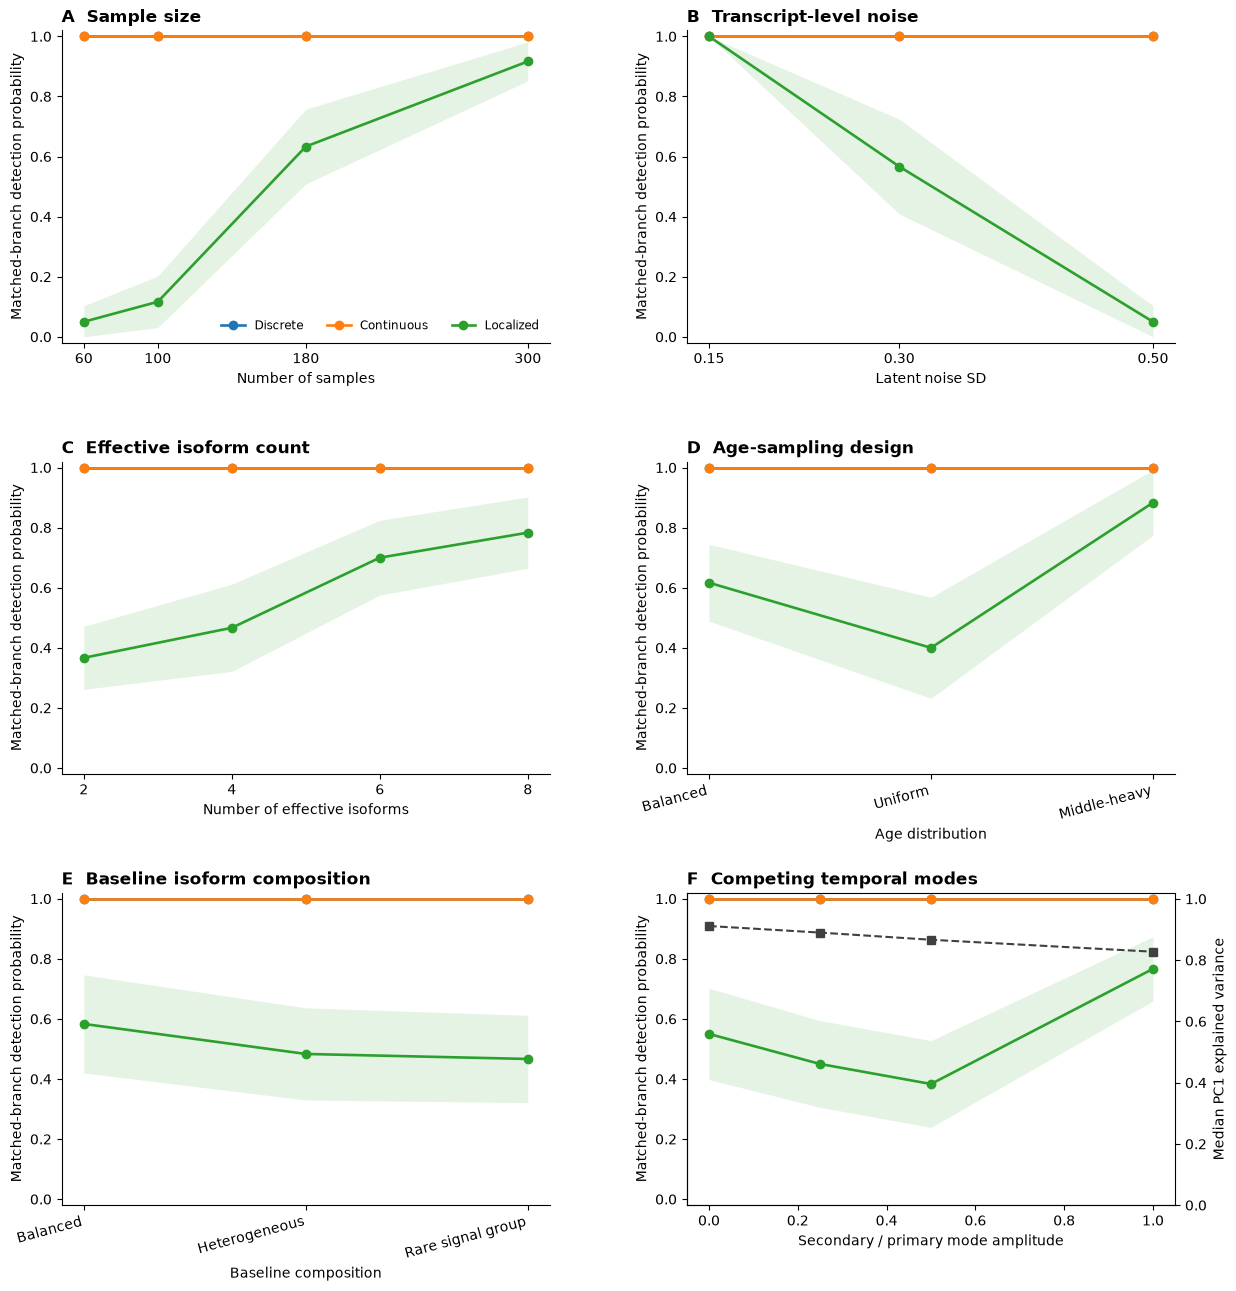

In [11]:
# ============================================================
# Plot design / robustness figure
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(12.8, 13.2),
)

fig.subplots_adjust(
    left=0.09,
    right=0.96,
    bottom=0.07,
    top=0.96,
    wspace=0.28,
    hspace=0.38,
)


PANELS = [
    (
        axes[0, 0],
        "sample_size",
        "A  Sample size",
        "Number of samples",
    ),

    (
        axes[0, 1],
        "noise_sd",
        "B  Transcript-level noise",
        "Latent noise SD",
    ),

    (
        axes[1, 0],
        "k",
        "C  Effective isoform count",
        "Number of effective isoforms",
    ),

    (
        axes[1, 1],
        "age_design",
        "D  Age-sampling design",
        "Age distribution",
    ),

    (
        axes[2, 0],
        "baseline_style",
        "E  Baseline isoform composition",
        "Baseline composition",
    ),
]


for (
    ax,
    factor,
    title,
    xlabel,
) in PANELS:

    levels = (
        ROBUSTNESS_GRID[
            factor
        ]
    )

    sub = (
        robustness_power.loc[
            robustness_power[
                "factor"
            ].eq(factor)
        ]
    )

    categorical = isinstance(
        levels[0],
        str,
    )

    if categorical:

        x_values = np.arange(
            len(levels)
        )

    else:

        x_values = np.asarray(
            levels,
            dtype=float,
        )

    for truth_type in (
        TRUTH_TYPES
    ):

        curve = (
            sub.loc[
                sub[
                    "truth_type"
                ].eq(
                    truth_type
                )
            ]
            .copy()
        )

        curve[
            "_order"
        ] = curve[
            "level"
        ].apply(
            lambda x:
                levels.index(
                    (
                        int(float(x))
                        if factor
                        in {
                            "sample_size",
                            "k",
                        }
                        else (
                            float(x)
                            if factor
                            == "noise_sd"
                            else x
                        )
                    )
                )
        )

        curve = curve.sort_values(
            "_order"
        )

        line, = ax.plot(
            x_values,
            curve[
                "mean"
            ],
            marker="o",
            lw=1.9,
            label=(
                truth_type.capitalize()
            ),
        )

        ax.fill_between(
            x_values,
            curve[
                "ci_low"
            ],
            curve[
                "ci_high"
            ],
            alpha=0.12,
            color=line.get_color(),
            linewidth=0,
        )

    if categorical:

        ax.set_xticks(
            x_values
        )

        ax.set_xticklabels(
            [
                DISPLAY_LABELS.get(
                    level,
                    str(level),
                )
                for level
                in levels
            ],
            rotation=15,
            ha="right",
        )

    else:

        ax.set_xticks(
            x_values
        )

    ax.set_ylim(
        -0.02,
        1.02,
    )

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        "Matched-branch detection probability"
    )

    ax.set_title(
        title,
        loc="left",
        fontweight="bold",
    )


# ============================================================
# F. Competing temporal modes
# ============================================================

ax = axes[
    2,
    1,
]

factor = (
    "secondary_mode_ratio"
)

levels = ROBUSTNESS_GRID[
    factor
]

sub = (
    robustness_power.loc[
        robustness_power[
            "factor"
        ].eq(factor)
    ]
)


for truth_type in (
    TRUTH_TYPES
):

    curve = (
        sub.loc[
            sub[
                "truth_type"
            ].eq(
                truth_type
            )
        ]
        .copy()
    )

    curve[
        "level"
    ] = pd.to_numeric(
        curve[
            "level"
        ]
    )

    curve = curve.sort_values(
        "level"
    )

    line, = ax.plot(
        curve[
            "level"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=(
            truth_type.capitalize()
        ),
    )

    ax.fill_between(
        curve[
            "level"
        ],
        curve[
            "ci_low"
        ],
        curve[
            "ci_high"
        ],
        alpha=0.12,
        color=line.get_color(),
        linewidth=0,
    )


ax.set_ylim(
    -0.02,
    1.02,
)

ax.set_xlabel(
    "Secondary / primary mode amplitude"
)

ax.set_ylabel(
    "Matched-branch detection probability"
)

ax.set_title(
    "F  Competing temporal modes",
    loc="left",
    fontweight="bold",
)


# Secondary axis:
# how strongly one-dimensional is the temporal variation?
ax2 = ax.twinx()

pc1_curve = (
    secondary_pc1.copy()
)

pc1_curve[
    "level"
] = pd.to_numeric(
    pc1_curve[
        "level"
    ]
)

pc1_curve = (
    pc1_curve.sort_values(
        "level"
    )
)

ax2.plot(
    pc1_curve[
        "level"
    ],
    pc1_curve[
        "mean"
    ],
    marker="s",
    ls="--",
    lw=1.5,
    color="0.25",
    label="PC1 variance",
)

ax2.set_ylim(
    0,
    1.02,
)

ax2.set_ylabel(
    "Median PC1 explained variance"
)


# ============================================================
# Shared cosmetics
# ============================================================

for ax in axes.ravel():

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


axes[
    0,
    0,
].legend(
    frameon=False,
    ncol=3,
    fontsize=8.5,
)

plt.show()